In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd #for numerical computing in Python
import numpy as np #Data manipulation and analysis library
import matplotlib.pyplot as plt #plotting and visualization library
import seaborn as sns  #Statistical data visualization based on Matplotlib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline


from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier



from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.metrics import roc_curve, auc

import shap
import os
import joblib

In [2]:
from google.colab import drive

drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [3]:
project_path = "/content/drive/My Drive/My project"
print(project_path)

/content/drive/My Drive/My project


In [4]:
raw_data_path = f"{project_path}/data/raw/original_dataset.csv"

data = pd.read_csv(raw_data_path)

print("\nFirst 5 Records:")
display(data.head())


First 5 Records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print("Shape:", data.shape)
print("\nData Types:")
print(data.dtypes)

Shape: (7043, 21)

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [6]:
print("\nMissing Values:")
#print(data.isna().mean().sort_values(ascending=False))
print(data.isna().sum())


Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [7]:
print("\nDuplicate Values:")
print(data.duplicated().sum())


Duplicate Values:
0


In [8]:
print("\nSummary Statistics:")
display(data.describe(include="all"))


Summary Statistics:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,3186-AJIEK,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [9]:
# Remove customerID (not useful for prediction)
df = data.drop("customerID", axis=1)

# covert TotalCharges to numeric value which contains white space strings for fresh accounts; coerce to float
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Handle missing values generated by coercion (impute with median)
df["TotalCharges"].fillna(df["TotalCharges"].median(), inplace=True)

print(f"{df.dtypes}")
df.head()


gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Churn
0    5174
1    1869
Name: count, dtype: int64


,proportion
Churn,
0,73.463013
1,26.536987


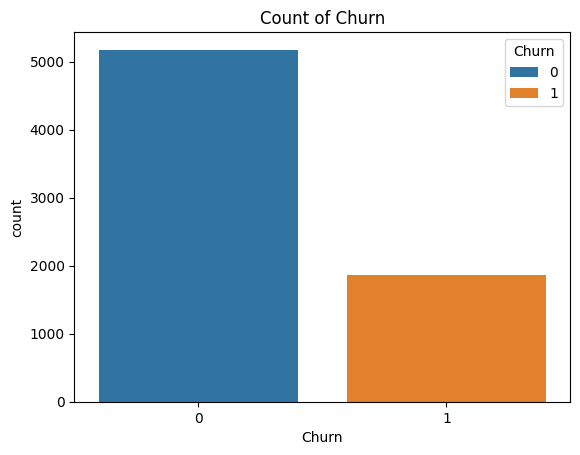

In [10]:
# Exploratory Data Analysis & Visualization
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
print(df["Churn"].value_counts())


sns.countplot(x = "Churn", data=df, hue="Churn") # We first check if the churn label balance or not
plt.title('Count of Churn')

df['Churn'].value_counts(normalize=True)*100    #The ratio for 'NO' is x3 higher than 'YES' label

In [11]:
# How many amount loss from customer churn
loss = []
for values in data.loc[data['Churn'] == 'Yes', 'TotalCharges']:
    value = float(values)
    loss.append(value)
print(f"we have lost around ${np.round(sum(loss))} due to customer churn")

we have lost around $2862927.0 due to customer churn


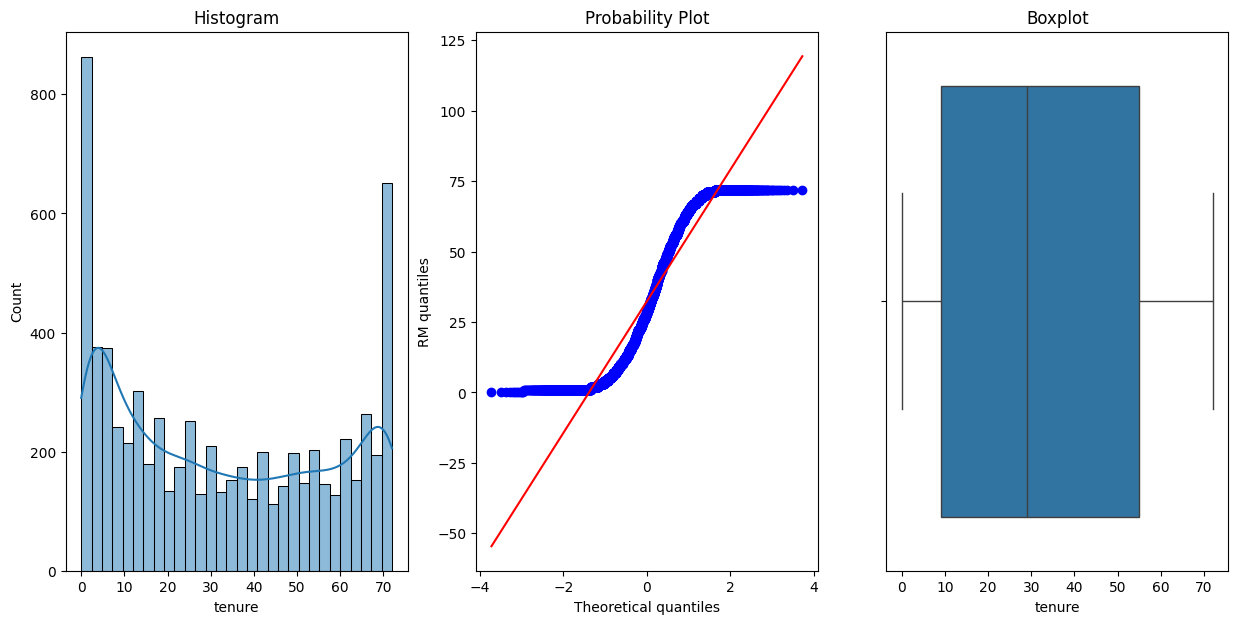

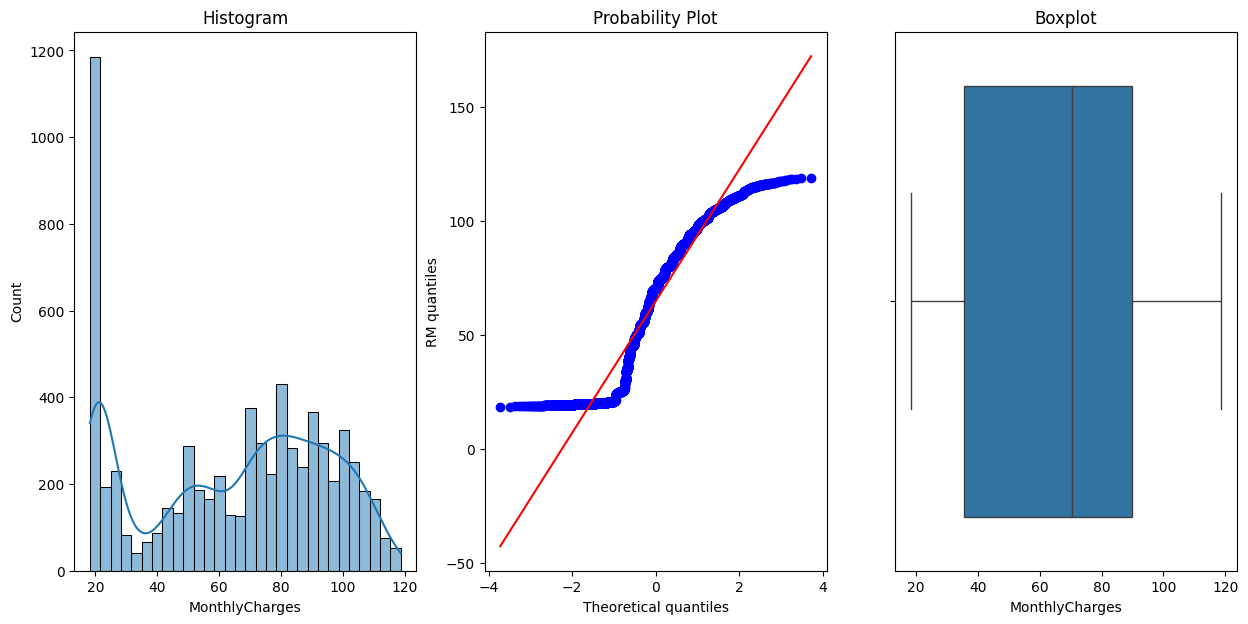

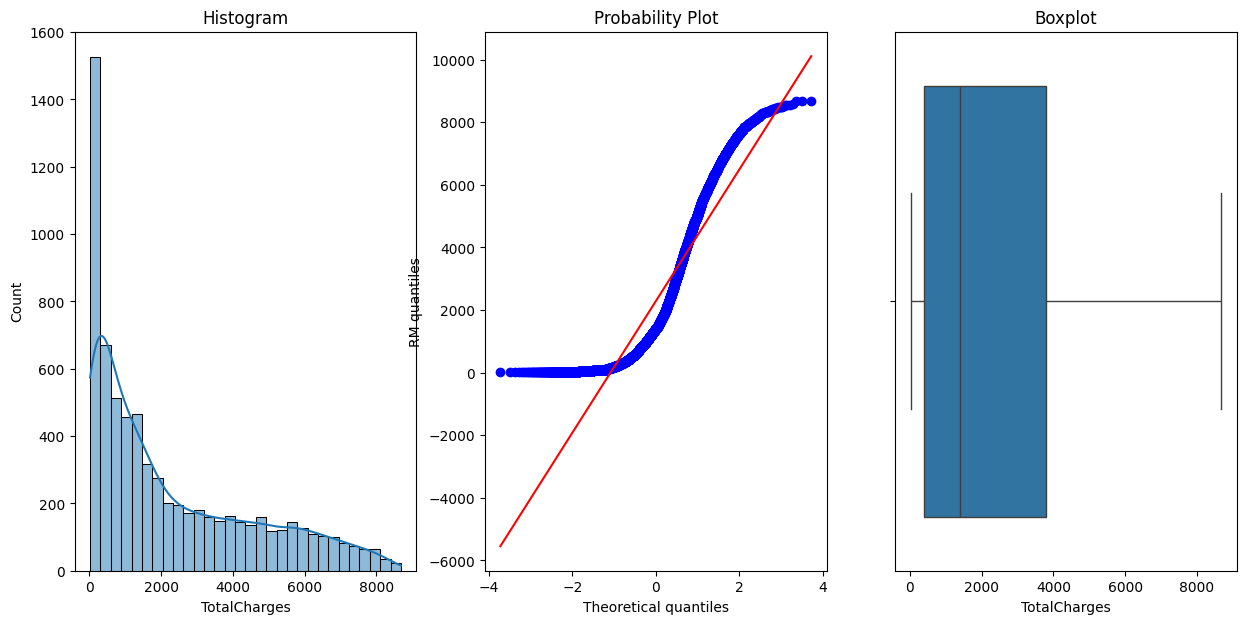

In [12]:
# Plotting numerical feature with probability distribution and checking outlier
import scipy.stats as stats

# Create a copy of the data for plotting
plot_data = df.copy()

#Assign numerical features to check the outliers
numerical_features= df.select_dtypes(include='number').columns

for feature in numerical_features:
    if feature != 'SeniorCitizen' and feature != 'Churn':
        plt.figure(figsize=(15,7))

        plt.subplot(1, 3, 1)
        sns.histplot(data=plot_data, x=feature, bins=30, kde=True)
        plt.title('Histogram')

        plt.subplot(1, 3, 2)
        stats.probplot(plot_data[feature], dist="norm", plot=plt)
        plt.ylabel('RM quantiles')

        plt.subplot(1, 3, 3)
        sns.boxplot(x=plot_data[feature])
        plt.title('Boxplot')

plt.show()

In [13]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for features in num_cols:
    q1 = df[features].quantile(0.25) #Calculates the 25th percentile
    q3 = df[features].quantile(0.75) #Calculates the 75th percentile
    iqr = q3 - q1   #Calculates the Interquartile Range, which measures the spread of the middle 50% of our data.
    lower_bound = q1 - 1.5 * iqr   #lower threshold boundaries
    upper_bound = q3 + 1.5 * iqr   #upper threshold boundaries

    # Filter rows that fall outside the bounds
    outliers = df[(df[features] < lower_bound) | (df[features] > upper_bound)]

    print(f"Feature: {features}")
    print(f"  Lower Bound: {lower_bound:.2f}")
    print(f"  Upper Bound: {upper_bound:.2f}")
    print(f"  Outlier Count: {len(outliers)}\n")

Feature: tenure
  Lower Bound: -60.00
  Upper Bound: 124.00
  Outlier Count: 0

Feature: MonthlyCharges
  Lower Bound: -46.02
  Upper Bound: 171.38
  Outlier Count: 0

Feature: TotalCharges
  Lower Bound: -4674.34
  Upper Bound: 8863.16
  Outlier Count: 0



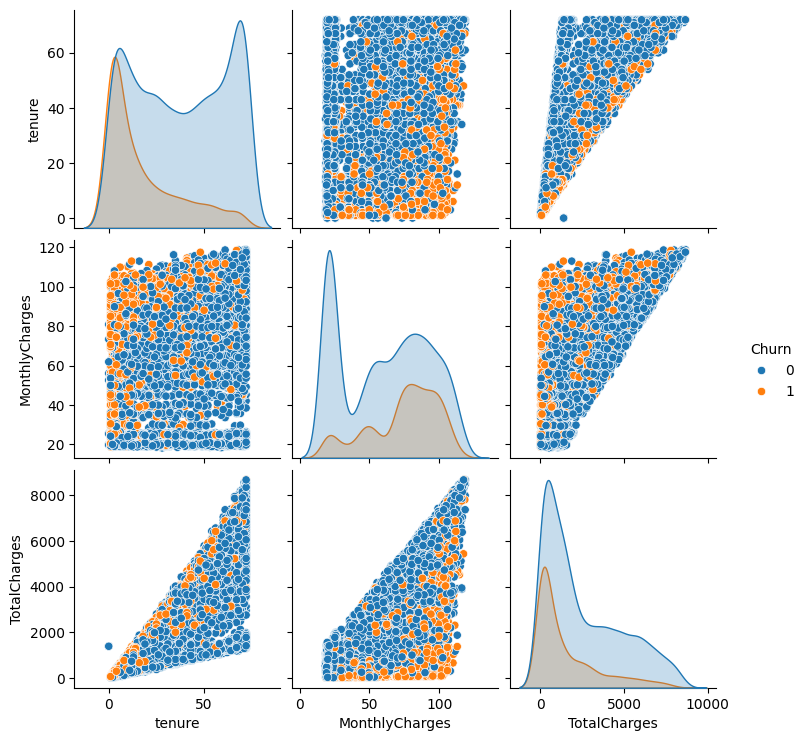

In [14]:
sns.pairplot(df.drop(columns='SeniorCitizen'), hue='Churn', kind='scatter')
plt.show()

Text(0.5, 1.0, 'percentage of Senior Citizens')

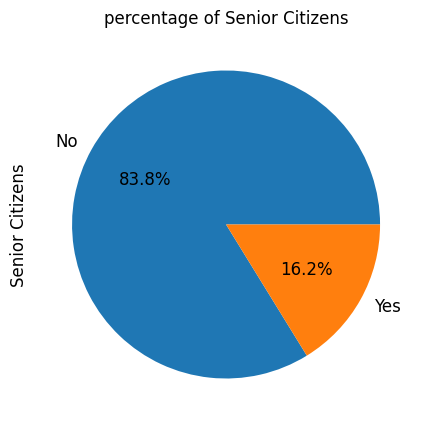

In [15]:
# pie chart for Count of Senior citizens
ax = (df['SeniorCitizen'].value_counts()*100.0 /len(data)).plot.pie(autopct='%.1f%%', labels = ['No', 'Yes'],figsize =(5,5), fontsize = 12 )
ax.set_ylabel('Senior Citizens',fontsize = 12)
ax.set_title('percentage of Senior Citizens', fontsize = 12)

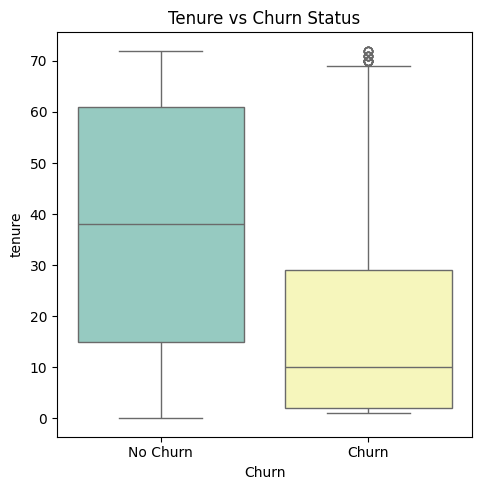

In [16]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 3)
sns.boxplot(data=df, x='Churn', y='tenure', palette='Set3')
plt.title('Tenure vs Churn Status')
plt.xticks([0, 1], ['No Churn', 'Churn'])

plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Monthly Charges Density by Churn')

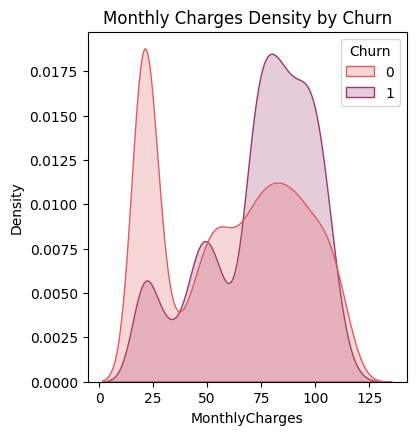

In [17]:
plt.figure(figsize=(14, 10))

plt.subplot(2, 3, 2)
sns.kdeplot(
    data=df,
    x='MonthlyCharges',
    hue='Churn',
    fill=True,
    common_norm=False,
    palette='flare',
)
plt.title('Monthly Charges Density by Churn')

Text(0.5, 1.0, 'Tenure Distribution by Churn')

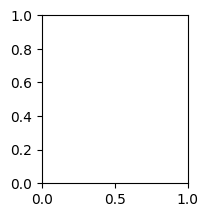

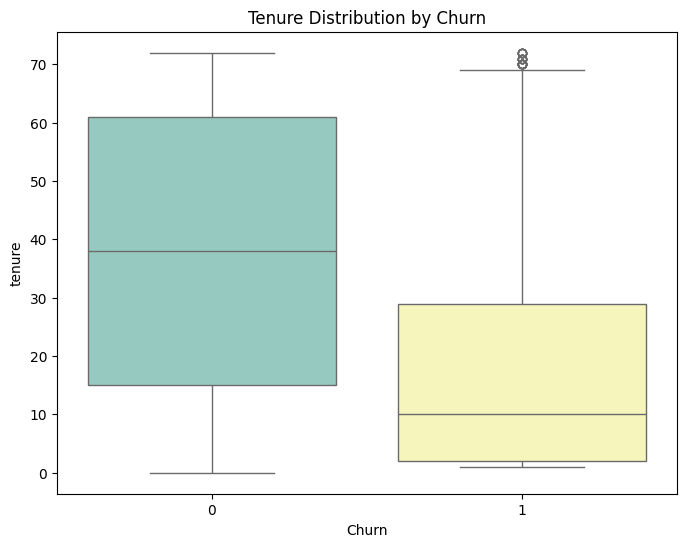

In [18]:
plt.subplot(2, 3, 4)
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='Churn', y='tenure', palette='Set3')
plt.title('Tenure Distribution by Churn')

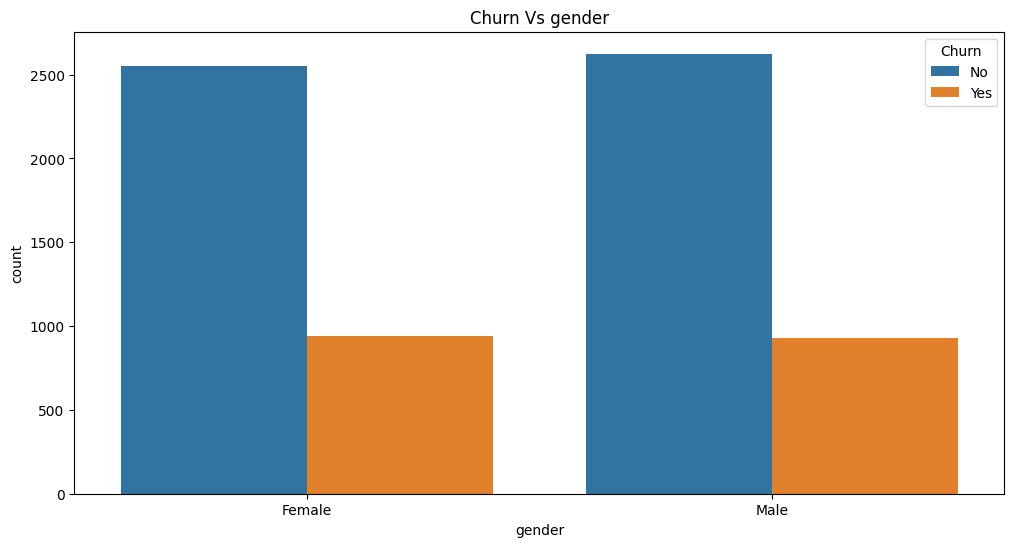

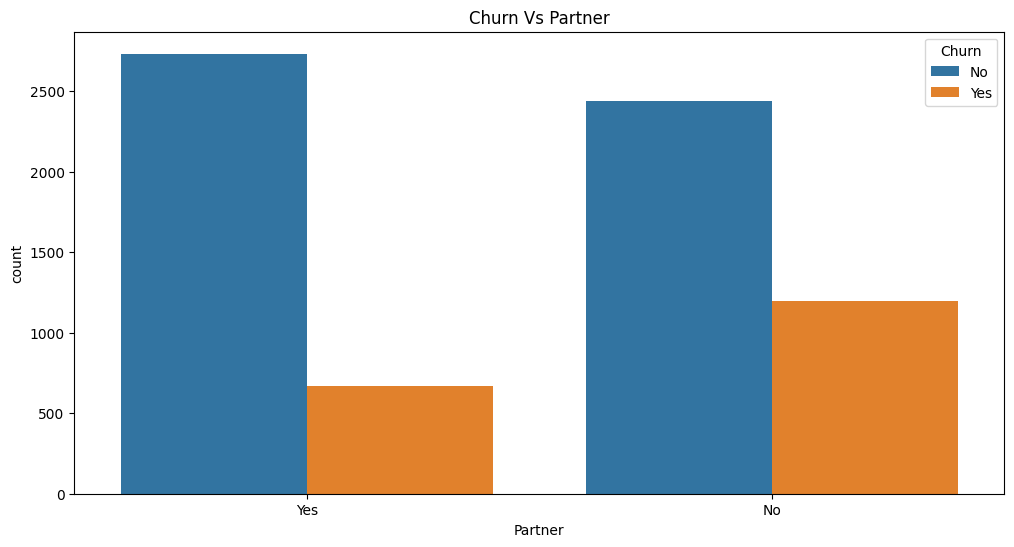

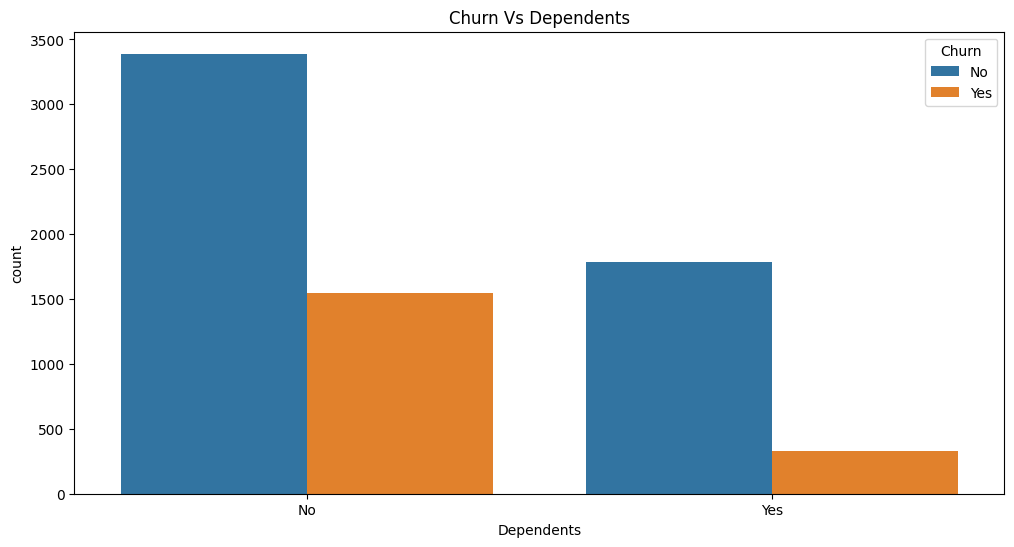

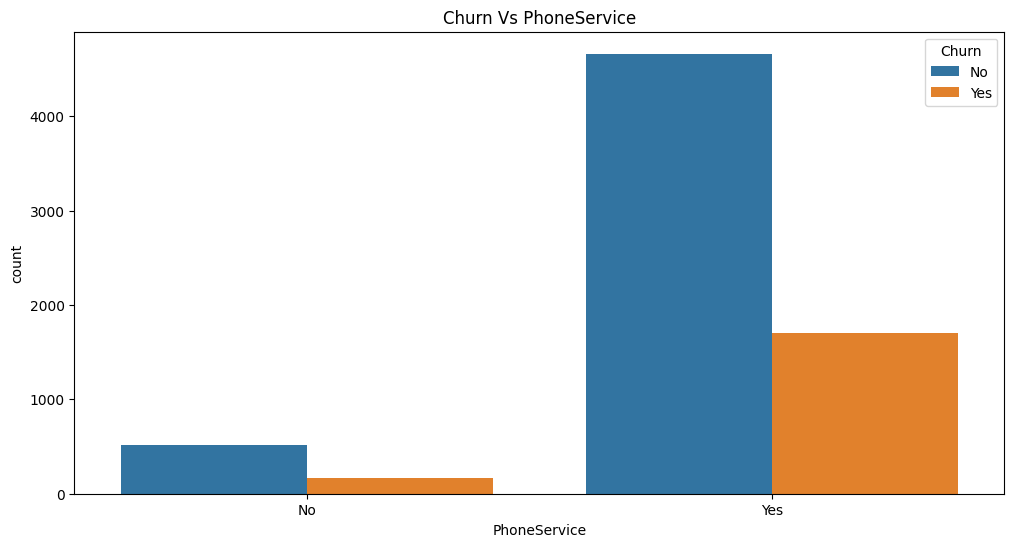

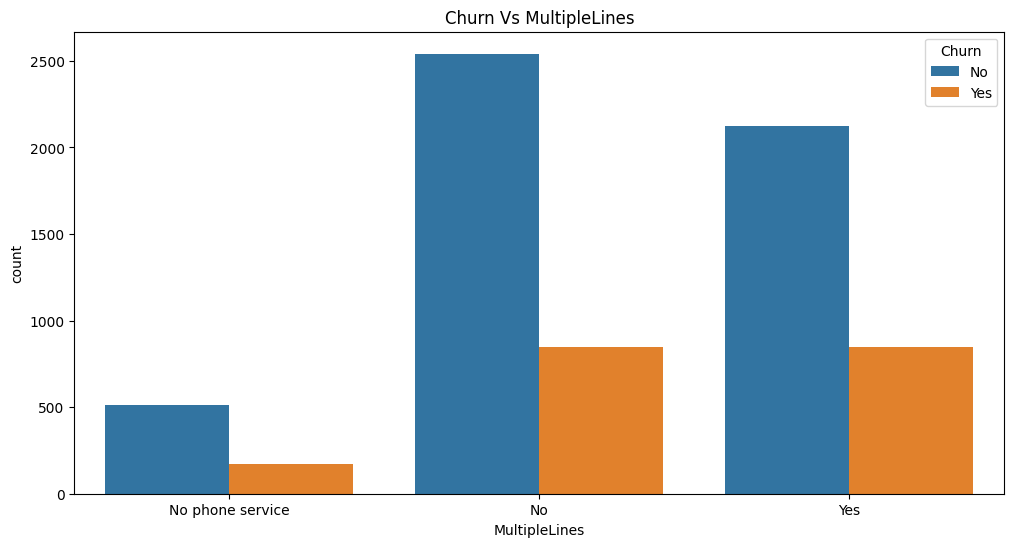

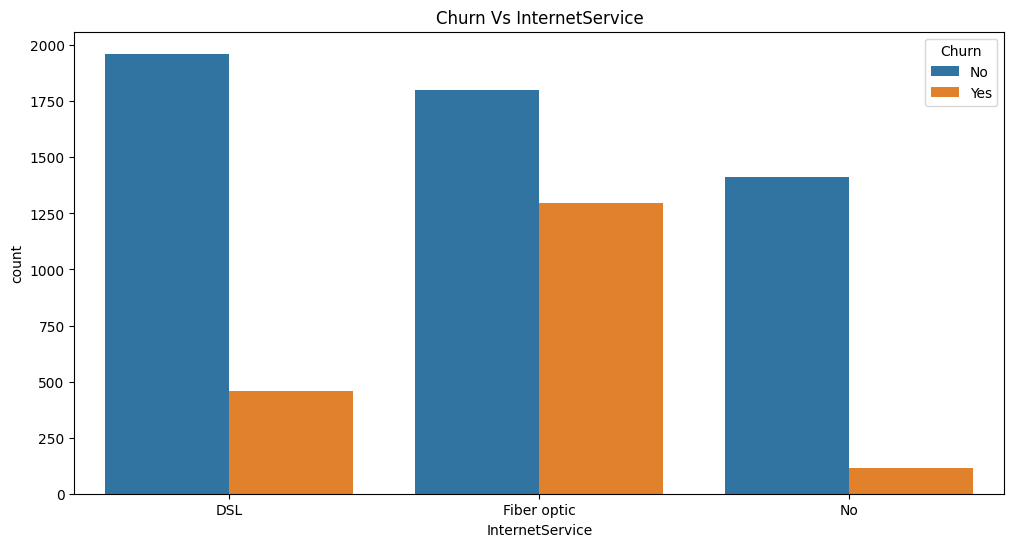

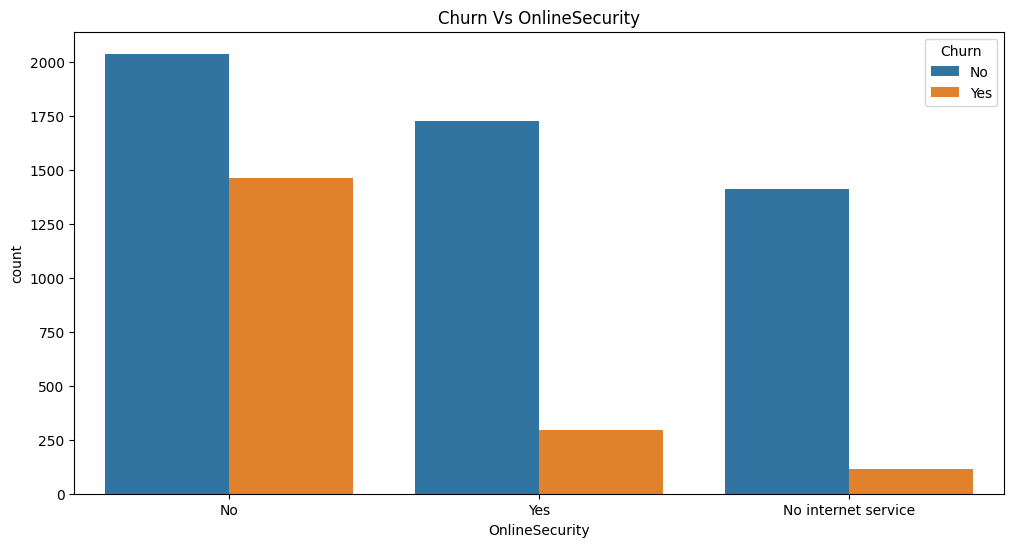

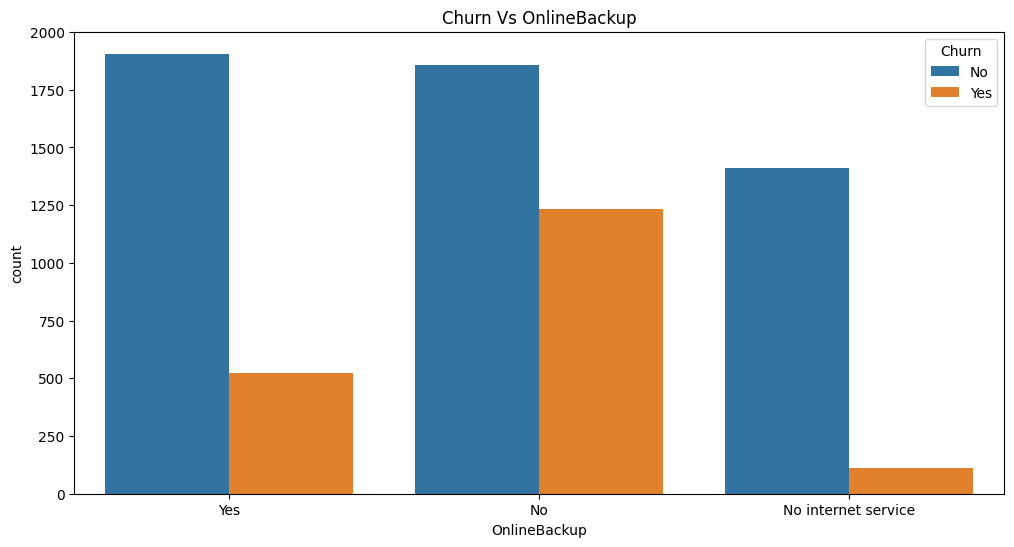

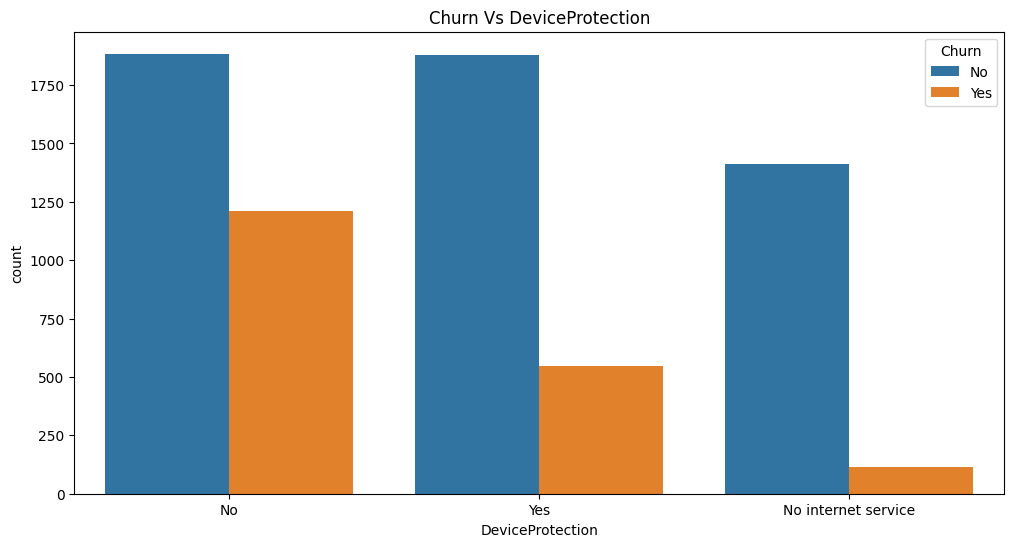

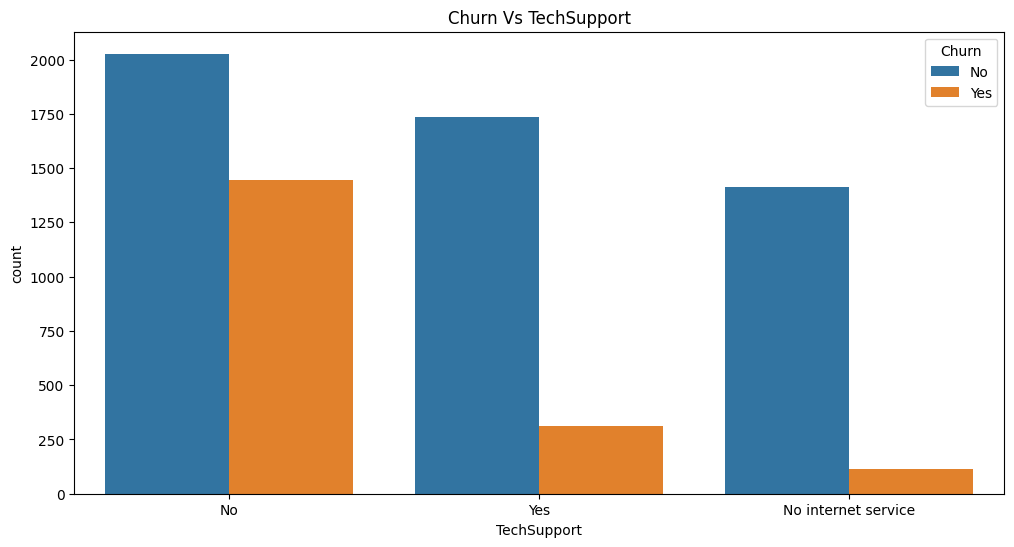

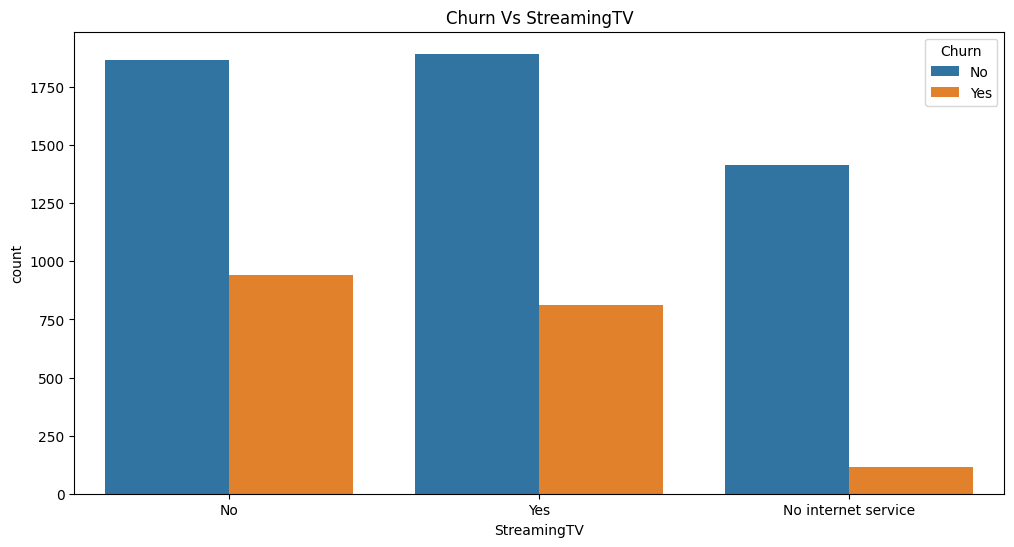

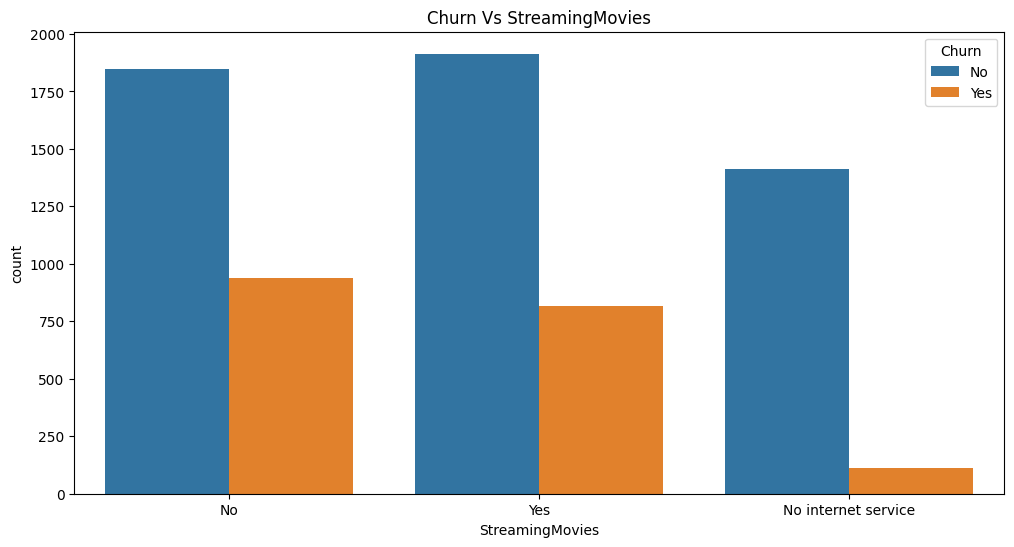

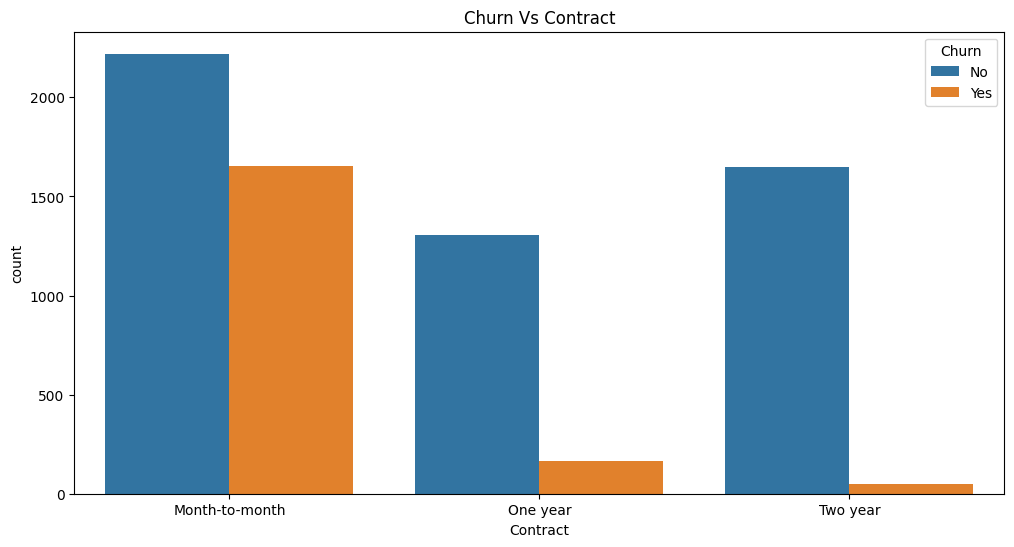

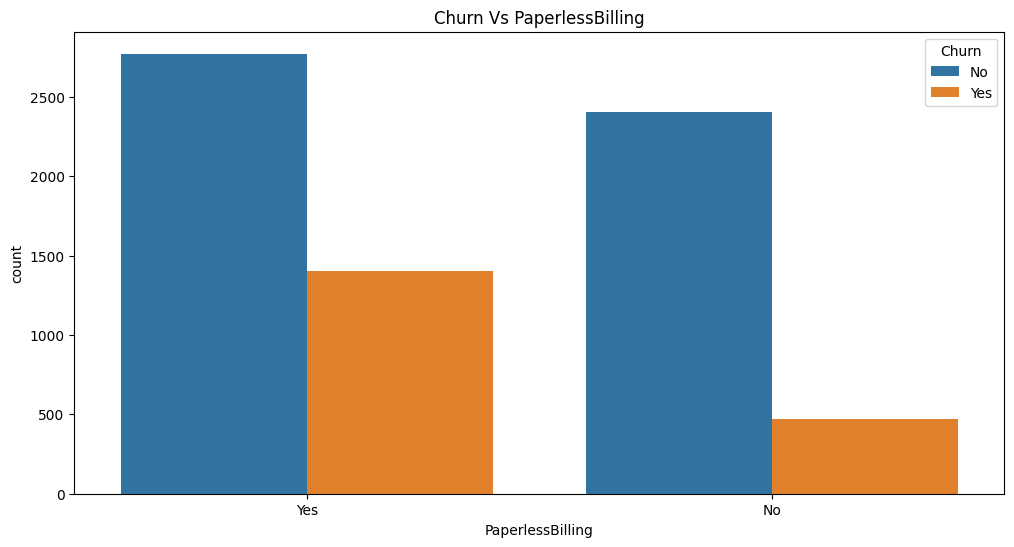

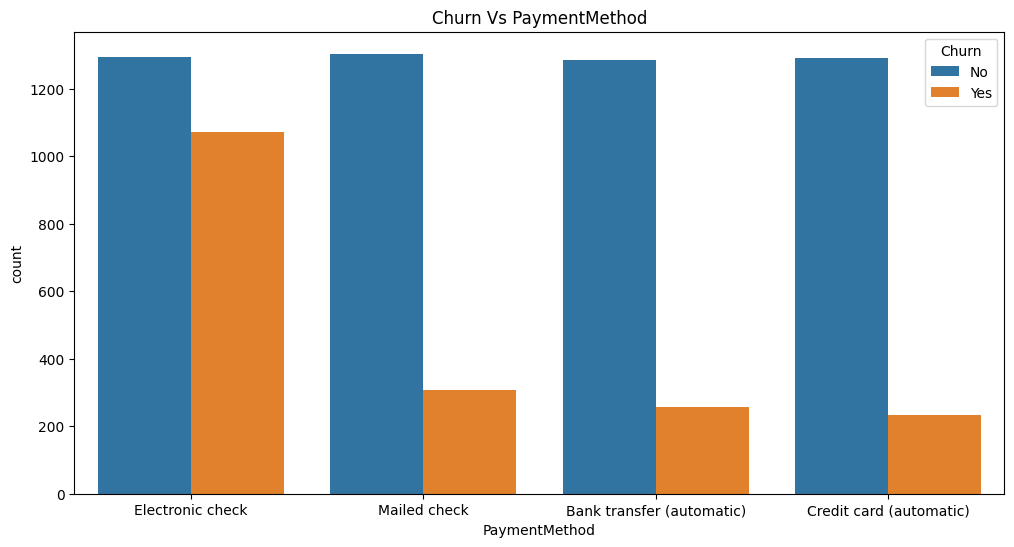

In [19]:
#Assign caegorical features to know the amount of customer chun in each Cateory
cateorical_features= df.select_dtypes(include='object').columns

for i, feature in enumerate(cateorical_features):
  plt.figure(figsize=(12, 6))
  sns.countplot(data=data, x=feature, hue='Churn')
  plt.title(f'Churn Vs {feature}')
  plt.show()


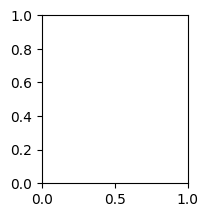

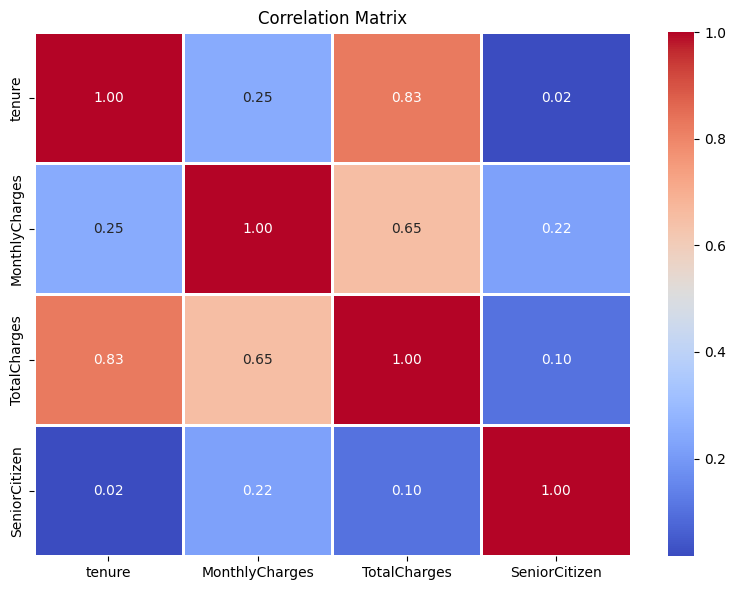

In [20]:
plt.subplot(2, 3, 6)
plt.figure(figsize=(8, 6))
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
sns.heatmap(
    df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=1
)
plt.title('Correlation Matrix')

plt.tight_layout()
plt.show()

In [21]:
# Monthly value ratio
df["ValueRatio"] = df["TotalCharges"] / (df["tenure"] + 1)

# Tenure group
df["TenureGroup"] = pd.cut(df["tenure"], bins=[0,12,24,36,72], labels=["New","Short","Medium","Long"])

# Calculate expected remaining lifetime value metrics

#Monthly_to_Total_Ratio
df['Monthly_to_Total_Ratio'] = df['MonthlyCharges'] / (df['TotalCharges'] + 1)

#Tenure_Charges_Interaction
df['Tenure_Charges_Interaction'] = df['tenure'] * df['MonthlyCharges']

#Total_Charges_to_Monthly_Ratio
df['Total_Charges_to_Monthly_Ratio'] = df['TotalCharges'] / (df['MonthlyCharges'] + 1)

In [22]:
df.head(5)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ValueRatio,TenureGroup,Monthly_to_Total_Ratio,Tenure_Charges_Interaction,Total_Charges_to_Monthly_Ratio
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,Yes,Electronic check,29.85,29.85,0,14.925000,New,0.967585,29.85,0.967585
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,Mailed check,56.95,1889.50,0,53.985714,Medium,0.030124,1936.30,32.605695
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,Yes,Mailed check,53.85,108.15,1,36.050000,New,0.493358,107.70,1.971741
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,No,Bank transfer (automatic),42.30,1840.75,0,40.016304,Long,0.022967,1903.50,42.511547
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,Yes,Electronic check,70.70,151.65,1,50.550000,New,0.463151,141.40,2.115063


In [23]:

# Define the processed data directory path
processed_data_dir = f"{project_path}/data/processed"

# Create directory if it does not exist
os.makedirs(processed_data_dir, exist_ok=True)

# Save the preprocessed DataFrame to Google Drive
saved_path = f"{processed_data_dir}/prepared_dataset.csv"
df.to_csv(saved_path, index=False)

print(f"Successfully saved prepared dataset to Google Drive: {saved_path}")

Successfully saved prepared dataset to Google Drive: /content/drive/My Drive/My project/data/processed/prepared_dataset.csv


In [24]:
# Define input features (X)
target= "Churn"

X = df.drop(target, axis=1)

# Define target variable (y)
y = df[target]

In [25]:
# Identify Categorical and Numerical Columns
categorical_cols = X.select_dtypes(include=['object', 'category']).columns
numerical_cols = X.select_dtypes(include=['number']).columns

In [26]:
print("Numerical columns:", list(numerical_cols))
print("Categorical columns:", list(categorical_cols))

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'ValueRatio', 'Monthly_to_Total_Ratio', 'Tenure_Charges_Interaction', 'Total_Charges_to_Monthly_Ratio']
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


In [27]:
print("Total Number of Numerical columns:", len(numerical_cols))
print("Total Number of Categorical columns:", len(categorical_cols))

Total Number of Numerical columns: 8
Total Number of Categorical columns: 16


In [28]:
# Data Preprocessing
#- Encode categorical variables
#- Scale numerical features
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, numerical_cols),
    ('cat', cat_pipeline, categorical_cols)
])

In [29]:
print(f"Numerical Pipeline:\n{num_pipeline}")
print(f"\nCategorical Pipeline:\n{cat_pipeline}")
print(f"\nCombined Preprocessor:\n{preprocessor}")

Numerical Pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])

Categorical Pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder',
                 OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

Combined Preprocessor:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges',
       'ValueRatio', 'Monthly_to_Total_Ratio', 'Tenure_Charges_Interaction',
       'Total_Charges_to_Monthly_Ratio'],
      dtype='object')),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                 

In [30]:
# First split: 80% training and 20% test data.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [31]:
print(f"X_train shape:{X_train.shape}")
print(f"X_test shape:{X_test.shape}")

X_train shape:(5634, 24)
X_test shape:(1409, 24)


In [32]:
# Standardize numerical features and encode categorical ones using the preprocessor pipeline.
# This prevents information from test sets leaking into training.

X_train_scaled = preprocessor.fit_transform(X_train)
#X_val_scaled = preprocessor.transform(X_val)
X_test_scaled = preprocessor.transform(X_test)

# Verify the transformation shape.
print("X_train preprocessed shape:", X_train_scaled.shape)
#print("X_val preprocessed shape:", X_val_scaled.shape)
print("X_test preprocessed shape:", X_test_scaled.shape)

X_train preprocessed shape: (5634, 53)
X_test preprocessed shape: (1409, 53)


In [33]:
# Show that stratification preserved a similar class distribution in each split.
split_distribution = pd.DataFrame({
    "Train": y_train.value_counts(normalize=True).sort_index(),
    "Test": y_test.value_counts(normalize=True).sort_index()}) * 100

split_distribution.index = ["No (0)", "Yes (1)"]
display(split_distribution.round(2))

,Train,Test
No (0),73.46,73.46
Yes (1),26.54,26.54
